# Eigen-analysis of the model operator

Adapted from `Kuang2008_v0.5.0/script/EigenAnalysis.jl`, using this project's
`Domain` and `Operator` classes and the parameters in `src/Params.py`.

For each configured angular wavenumber $k$, solve $A(k)v_j=\lambda_jv_j$ and rank
modes independently by **descending real part** of the eigenvalue. With the
Fourier convention $e^{ikx+\lambda t}$:

- Growth rate: $\mathrm{Re}(\lambda)$, in day$^{-1}$ using the Julia reference time of one day.
- Phase speed: $-\mathrm{Im}(\lambda)/k \times L_{\rm ref}/T_{\rm ref}$, in m s$^{-1}$,
  where $L_{\rm ref}=4{,}320{,}000$ m and $T_{\rm ref}=86{,}400$ s.

The Python domain supplies the wavenumber grid; it need not match the Julia TOML grid.
`domain.k` is used in the operator and phase-speed formula, while `domain.nondim_k`
is the zonal wavenumber used on the plots. Unlike the Julia script's real-matrix
conversion, this notebook preserves complex coefficients for the one-way system.
There are four modes for `one-way` and six for `two-way`.

**Mode rank is not a continuously tracked physical branch.** Equal-growth modes
(such as conjugate pairs) have no unique growth-based ordering, and ranks can swap
between neighboring wavenumbers. Phase speed at $k=0$ is undefined and stored as NaN.

## Imports

In [ ]:
import sys
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt

# Locate the project when launched from either its root or scripts directory.
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "Operators.py").is_file()
     and (path / "src" / "Domain.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Launch this notebook from Kuang-python or its scripts directory.")
src_path = str(project_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from Domain import Domain
from Operators import Operator

## Configuration

Compare radiation scaling factors `0.0` and `1.0` using the same model parameters
and wavenumber grid. Change `model_type` and rerun the following cells to switch
between the one-way and two-way systems.

In [ ]:
model_type = "two-way"       # "one-way" or "two-way"
rad_scalings = (0.0, 1.0)
line_styles = {0.0: "-", 1.0: "--"}

reference_length_m = 4_320_000.0
reference_time_s = 86_400.0
speed_scale = reference_length_m / reference_time_s  # 50 m/s

domain = Domain()
nondim_k = np.asarray(domain.nondim_k, dtype=float)
k = np.asarray(domain.k, dtype=float)
operator = Operator(model_type)
print(f"Model: {model_type}; radiation scalings: {rad_scalings}; wavenumbers: {k.size}")

Model: two-way; radiation scalings: (0.0, 1.0); wavenumbers: 61


## Compute and rank eigenmodes

In [ ]:
def eigen_analysis(operator, wavenumbers, rad_scaling, speed_scale=50.0):
    """Return ranked eigenvalues, eigenvectors, growth rates, and phase speeds.

    Eigenvalues, growth rates, and phase speeds have shape (n_modes, n_k).
    Eigenvectors have shape (n_state, n_modes, n_k), with modes in columns.
    Sorting is independent at each k, as in the Julia reference script.
    """
    wavenumbers = np.asarray(wavenumbers, dtype=float)
    if wavenumbers.ndim != 1 or wavenumbers.size == 0:
        raise ValueError("wavenumbers must be a nonempty one-dimensional array.")
    if not np.all(np.isfinite(wavenumbers)):
        raise ValueError("wavenumbers must contain only finite values.")
    if not np.isfinite(rad_scaling):
        raise ValueError("rad_scaling must be finite.")
    if not np.isfinite(speed_scale) or speed_scale <= 0:
        raise ValueError("speed_scale must be finite and positive.")

    ranked_values = []
    ranked_vectors = []
    for kn in wavenumbers:
        matrix = np.asarray(operator.operator(float(kn), rad_scaling))
        values, vectors = np.linalg.eig(matrix)
        order = np.argsort(-values.real, kind="stable")
        ranked_values.append(values[order])
        ranked_vectors.append(vectors[:, order])

    eigenvalues = np.stack(ranked_values, axis=1)
    eigenvectors = np.stack(ranked_vectors, axis=2)
    growth_rates = eigenvalues.real.copy()
    phase_speeds = np.full(eigenvalues.shape, np.nan, dtype=float)
    np.divide(
        -eigenvalues.imag * speed_scale,
        wavenumbers[None, :],
        out=phase_speeds,
        where=wavenumbers[None, :] != 0,
    )
    return eigenvalues, eigenvectors, growth_rates, phase_speeds



def dominant_mode_indices(eigenvalues, phase_speeds):
    """Select maximal growth, preferring positive phase speed for conjugate ties.

    Equal growth is tested within numerical tolerance. The selected mode can
    change physical branches as k varies; this is a maximum-growth comparison,
    not a continuous eigenmode tracking algorithm.
    """
    indices = np.empty(eigenvalues.shape[1], dtype=int)
    for i in range(eigenvalues.shape[1]):
        growth = eigenvalues[:, i].real
        candidates = np.flatnonzero(
            np.isclose(growth, growth.max(), rtol=1e-10, atol=1e-12)
        )
        speeds = phase_speeds[candidates, i]
        if np.any(np.isfinite(speeds)):
            indices[i] = candidates[np.nanargmax(speeds)]
        else:
            indices[i] = candidates[0]  # Phase speed is undefined at k = 0.
    return indices


results = {}
for rad_scaling in rad_scalings:
    eigenvalues, eigenvectors, growth_rates, phase_speeds = eigen_analysis(
        operator, k, rad_scaling, speed_scale
    )
    selected = dominant_mode_indices(eigenvalues, phase_speeds)
    columns = np.arange(k.size)
    results[rad_scaling] = {
        "eigenvalues": eigenvalues,
        "eigenvectors": eigenvectors,
        "growth_rates": growth_rates,
        "phase_speeds": phase_speeds,
        "dominant_indices": selected,
        "dominant_growth": growth_rates[selected, columns],
        "dominant_speed": phase_speeds[selected, columns],
    }
    print(f"Radiation scaling {rad_scaling:.1f}: {growth_rates.shape} (mode, wavenumber)")

Radiation scaling 0.0: (6, 61) (mode, wavenumber)
Radiation scaling 1.0: (6, 61) (mode, wavenumber)


## Check the eigenpairs

Verify both the descending growth ranking and the residual $Av-\lambda v$
for every eigenvector at every sampled wavenumber.

In [ ]:
for rad_scaling, result in results.items():
    eigenvalues = result["eigenvalues"]
    eigenvectors = result["eigenvectors"]
    growth_rates = result["growth_rates"]
    assert np.all(np.isfinite(eigenvalues))
    assert np.all(np.diff(growth_rates, axis=0) <= 0)
    np.testing.assert_allclose(
        result["dominant_growth"], growth_rates.max(axis=0), rtol=1e-10, atol=1e-12
    )
    relative_residuals = np.empty(k.size)
    for i, kn in enumerate(k):
        matrix = operator.operator(float(kn), rad_scaling)
        vectors = eigenvectors[:, :, i]
        values = eigenvalues[:, i]
        residual = matrix @ vectors - vectors * values[None, :]
        denominator = np.maximum(
            (np.linalg.norm(matrix, ord=2) + np.abs(values))
            * np.linalg.norm(vectors, axis=0),
            np.finfo(float).tiny,
        )
        relative_residuals[i] = np.max(np.linalg.norm(residual, axis=0) / denominator)
    assert relative_residuals.max() < 1e-10
    peak_index = int(np.argmax(result["dominant_growth"]))
    print(f"Radiation scaling {rad_scaling:.1f}")
    print(f"  Maximum relative eigenpair residual: {relative_residuals.max():.3e}")
    print(f"  Peak growth: {result['dominant_growth'][peak_index]:.6g} day^-1 "
          f"at zonal wavenumber {nondim_k[peak_index]:g}")
    print(f"  Corresponding phase speed: {result['dominant_speed'][peak_index]:.6g} m/s")

Radiation scaling 0.0
  Maximum relative eigenpair residual: 9.560e-16
  Peak growth: 0.128188 day^-1 at zonal wavenumber 7.5
  Corresponding phase speed: 20.8402 m/s
Radiation scaling 1.0
  Maximum relative eigenpair residual: 7.181e-16
  Peak growth: 0.0560529 day^-1 at zonal wavenumber 6.5
  Corresponding phase speed: 20.0486 m/s


## Radiation comparison: fastest-growing mode

Both panels use **black lines**: solid for radiation scaling **0.0** and dashed
for **1.0**. The left panel shows the largest growth rate at each wavenumber;
the right panel shows the phase speed of the same selected eigenmode.

For conjugate modes with equal growth, select the positive-phase-speed member
consistently. Signed phase speeds are retained for modes without such a tie.
This selects the fastest-growing mode independently at each wavenumber, so a
physical branch change can still cause a discontinuity. The growth-rate panel
retains the zero lower limit to emphasize unstable modes; negative growth rates
remain available in `results`.

The figure is also saved as PNG and PDF in `output/eigen_analysis/`.

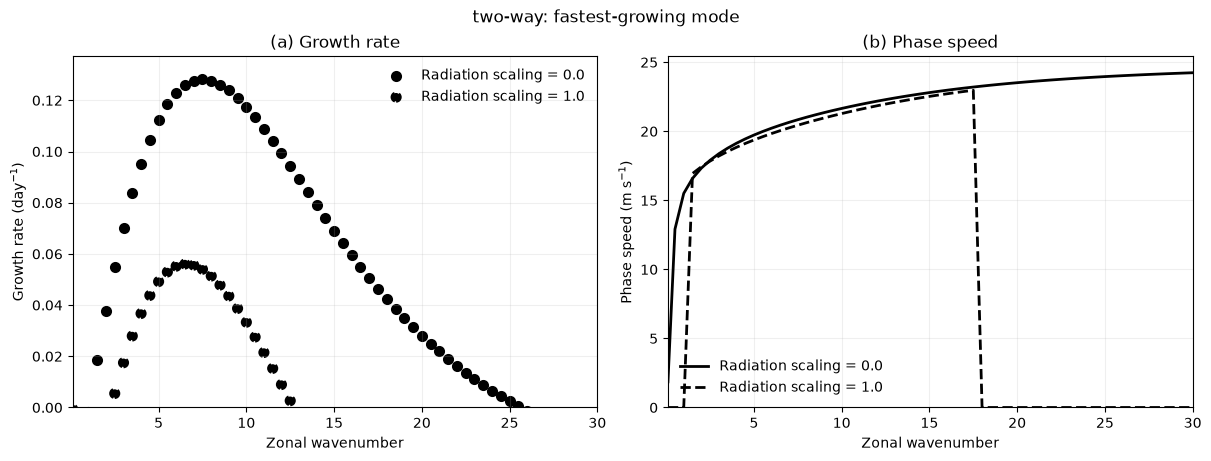

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for rad_scaling in rad_scalings:
    result = results[rad_scaling]
    style = dict(color="black", linestyle=line_styles[rad_scaling], linewidth=2.0,
                 label=f"Radiation scaling = {rad_scaling:.1f}")
    axes[0].plot(nondim_k, result["dominant_growth"], **style)
    axes[1].plot(nondim_k, result["dominant_speed"], **style)

axes[0].set_title("(a) Growth rate")
axes[1].set_title("(b) Phase speed")
axes[0].set_ylabel(r"Growth rate (day$^{-1}$)")
axes[1].set_ylabel(r"Phase speed (m s$^{-1}$)")
axes[0].set_ylim(0, None)
axes[1].set_ylim(0, None)
for ax in axes:
    ax.set_xlabel("Zonal wavenumber")
    ax.set_xlim(nondim_k.min(), nondim_k.max())
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
fig.suptitle(f"{model_type}: fastest-growing mode")

figure_dir = project_root / "output" / "eigen_analysis"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_dir / f"{model_type}_radiation_comparison"
fig.savefig(figure_path.with_suffix(".png"), dpi=200)
fig.savefig(figure_path.with_suffix(".pdf"))
plt.show()